In [50]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/astana_rent_clean.csv")
print(df.shape)

train, test = train_test_split(df, test_size=0.25, random_state=42)
print(train.shape, test.shape)

(600, 15)
(450, 15) (150, 15)


In [51]:
from sklearn.linear_model import LinearRegression

# Убираем пропуски площади для парной регрессии
tr = train.dropna(subset=["area"])

# Формируем матрицу X: первый столбец - единицы (для w0), второй - площадь
X = np.column_stack([np.ones(len(tr)), tr["area"]])
y = tr["price"].to_numpy()

# Решаем уравнение (X^T * X) * w = X^T * y
w = np.linalg.solve(X.T @ X, X.T @ y)
print("Веса по формуле:", w.round(1))

# Сверяем с LinearRegression из sklearn
lr = LinearRegression().fit(tr[["area"]], y)
print("Веса sklearn:", round(lr.intercept_, 1), lr.coef_.round(1))

Веса по формуле: [9122.1 4265.1]
Веса sklearn: 9122.1 [4265.1]


In [52]:
from sklearn.metrics import mean_squared_error, r2_score

# Считаем ошибку на обучении через векторы
mse = np.square(X @ w - y).mean()
print("Train RMSE:", round(np.sqrt(mse)))

# Проверяем модель на отложенной тестовой выборке
te = test.dropna(subset=["area"])
pred = lr.predict(te[["area"]])
print("Test RMSE:", round(np.sqrt(mean_squared_error(te["price"], pred))))
print("Test R2:", round(r2_score(te["price"], pred), 3))

Train RMSE: 47045
Test RMSE: 47198
Test R2: 0.756


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Делим признаки на числовые и категориальные (убрали "dist_center")
num_cols = ["rooms", "area", "floor", "floors", "year"]
cat_cols = ["district", "furniture"]

# Целевые переменные называются "price"
X_train, y_train = train[num_cols + cat_cols], train["price"]
X_test, y_test = test[num_cols + cat_cols], test["price"]

# Собираем предобработку
def make_prep(num=num_cols):
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cat_cols)
    )

# Собираем итоговую модель
model = make_pipeline(make_prep(), LinearRegression())

# Оцениваем на кросс-валидации
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
print("R2 по фолдам:", scores.round(3))
print("Средний R2 (CV):", scores.mean().round(3))

# Обучаем финально и смотрим веса
model.fit(X_train, y_train)
print("Test R2:", round(model.score(X_test, y_test), 3))

# Выводим веса
names = [n.split("_")[1] if "_" in n and len(n.split("_")) > 1 else n for n in model[:-1].get_feature_names_out()]
coefs = pd.Series(model[-1].coef_, index=names)
print("\nВеса признаков:\n", coefs.round(0).sort_values())

R2 по фолдам: [0.931 0.904 0.89  0.924 0.933]
Средний R2 (CV): 0.916
Test R2: 0.914

Веса признаков:
    -32274.0
   -23170.0
   -13846.0
    -5736.0
    -1128.0
     1215.0
     1287.0
     5736.0
    11697.0
    14562.0
    57594.0
    85605.0
dtype: float64


In [54]:
from sklearn.linear_model import RidgeCV, LassoCV

# Задаем сетку коэффициентов альфа для перебора
regs = {
    "ridge": RidgeCV(alphas=np.logspace(-2, 3, 30)),
    "lasso": LassoCV(alphas=np.logspace(0, 4, 30), cv=5, random_state=42, max_iter=50000)
}

for name, reg in regs.items():
    # Собираем пайплайн: наша старая предобработка + новая модель с регуляризацией
    m = make_pipeline(make_prep(), reg)
    
    # Оцениваем на кросс-валидации
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean()
    m.fit(X_train, y_train)
    
    # Считаем, сколько весов модель превратила в строгий 0
    zeros = int((np.abs(m[-1].coef_) < 1e-6).sum())
    
    print(name, "alpha:", round(m[-1].alpha_, 3), 
          "| cv R2:", cv.round(3), 
          "| test R2:", round(m.score(X_test, y_test), 3), 
          "| обнулено весов:", zeros, "из", len(m[-1].coef_))

ridge alpha: 0.356 | cv R2: 0.916 | test R2: 0.915 | обнулено весов: 0 из 12
lasso alpha: 4.894 | cv R2: 0.916 | test R2: 0.914 | обнулено весов: 2 из 12


In [55]:
from sklearn.linear_model import Ridge
# Базовый R2 нашей лучшей модели (Ridge)
base = cross_val_score(make_pipeline(make_prep(), Ridge(alpha=1)), 
                       X_train, y_train, cv=5, scoring="r2").mean()

drop = {}
for col in num_cols + cat_cols:
    nn = [c for c in num_cols if c != col]
    cc = [c for c in cat_cols if c != col]
    
    prep = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nn),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cc)
    )
    
    s = cross_val_score(make_pipeline(prep, Ridge(alpha=1)), 
                        X_train, y_train, cv=5, scoring="r2").mean()
    drop[col] = base - s

print("Падение R2 при удалении признака:")
print(pd.Series(drop).sort_values(ascending=False).round(3))

Падение R2 при удалении признака:
area         0.150
district     0.140
year         0.027
furniture    0.004
floor       -0.000
rooms       -0.000
floors      -0.000
dtype: float64


In [56]:
# П2. Формула МНК

import time

# 1. Берем самый сильный числовой признак (площадь)
X_area = train[['area']].dropna()
y_area = train.loc[X_area.index, 'price'].to_numpy()
X_area_b = np.column_stack([np.ones(len(X_area)), X_area])

# 2. Вычисляем веса тремя способами и замеряем время
print("Способ 1: np.linalg.inv (X.T @ X) @ X.T @ y")
t0 = time.time()
w1 = np.linalg.inv(X_area_b.T @ X_area_b) @ X_area_b.T @ y_area
print(f"Веса: {w1.round(2)}, Время: {time.time() - t0:.6f} с\n")

print("Способ 2: np.linalg.solve(X.T @ X, X.T @ y)")
t0 = time.time()
w2 = np.linalg.solve(X_area_b.T @ X_area_b, X_area_b.T @ y_area)
print(f"Веса: {w2.round(2)}, Время: {time.time() - t0:.6f} с\n")

print("Способ 3: np.linalg.lstsq(X, y, rcond=None)")
t0 = time.time()
w3, residuals, rank, s = np.linalg.lstsq(X_area_b, y_area, rcond=None)
print(f"Веса: {w3.round(2)}, Время: {time.time() - t0:.6f} с\n")

print("Способ 4: LinearRegression()")
t0 = time.time()
lr_area = LinearRegression().fit(X_area, y_area)
print(f"Веса: {[lr_area.intercept_, lr_area.coef_[0]]}, Время: {time.time() - t0:.6f} с\n")

# 3. Добавляем копию столбца и смотрим, что сломается
X_collinear = np.column_stack([X_area_b, X_area])
print("--- Добавили копию столбца (линейная зависимость) ---")

try:
    print("inv:", (np.linalg.inv(X_collinear.T @ X_collinear) @ X_collinear.T @ y_area).round(2))
except np.linalg.LinAlgError as e:
    print(f"inv: Ошибка! {e}")

try:
    print("solve:", np.linalg.solve(X_collinear.T @ X_collinear, X_collinear.T @ y_area).round(2))
except np.linalg.LinAlgError as e:
    print(f"solve: Ошибка! {e}")

print("lstsq:", np.linalg.lstsq(X_collinear, y_area, rcond=None)[0].round(2))

Способ 1: np.linalg.inv (X.T @ X) @ X.T @ y
Веса: [9122.07 4265.12], Время: 0.001001 с

Способ 2: np.linalg.solve(X.T @ X, X.T @ y)
Веса: [9122.07 4265.12], Время: 0.000000 с

Способ 3: np.linalg.lstsq(X, y, rcond=None)
Веса: [9122.07 4265.12], Время: 0.000991 с

Способ 4: LinearRegression()
Веса: [np.float64(9122.067275167763), np.float64(4265.121632971329)], Время: 0.003128 с

--- Добавили копию столбца (линейная зависимость) ---
inv: Ошибка! Singular matrix
solve: Ошибка! Singular matrix
lstsq: [9122.07 2132.56 2132.56]


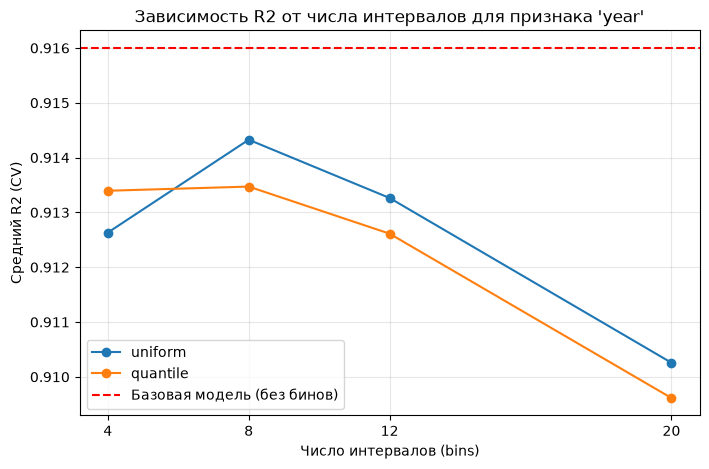

strategy  quantile  uniform
bins                       
4            0.913    0.913
8            0.913    0.914
12           0.913    0.913
20           0.910    0.910


In [57]:
# П3. Бинаризация признака 'year'

from sklearn.preprocessing import KBinsDiscretizer
import matplotlib.pyplot as plt

num_wo = ["rooms", "area", "floor", "floors"]

def make_prep_bins(n_bins=8, strategy="uniform"):
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_wo),
        (make_pipeline(SimpleImputer(strategy="median"), 
                       KBinsDiscretizer(n_bins=n_bins, encode="onehot", strategy=strategy)), ["year"]),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cat_cols)
    )

results = []
bin_counts = [4, 8, 12, 20]

for strategy in ["uniform", "quantile"]:
    for n in bin_counts:
        m = make_pipeline(make_prep_bins(n_bins=n, strategy=strategy), LinearRegression())
        score = cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean()
        results.append({"strategy": strategy, "bins": n, "r2": score})

res_df = pd.DataFrame(results)

# Строим график
plt.figure(figsize=(8, 5))
for strategy in ["uniform", "quantile"]:
    subset = res_df[res_df["strategy"] == strategy]
    plt.plot(subset["bins"], subset["r2"], marker='o', label=strategy)

plt.axhline(0.916, color='red', linestyle='--', label='Базовая модель (без бинов)')
plt.title("Зависимость R2 от числа интервалов для признака 'year'")
plt.xlabel("Число интервалов (bins)")
plt.ylabel("Средний R2 (CV)")
plt.xticks(bin_counts)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(res_df.pivot(index="bins", columns="strategy", values="r2").round(3))